# Reentrenamiento con Transfer Learning y más categorías

## 1. Descripción

Este notebook amplía la clasificación del modelo anterior usando **Transfer Learning** con **MobileNetV2**, una red ya entrenada con millones de imágenes de ImageNet.

Se amplía el número de clases de **3 a 5 razas**:
* **bulldog**
* **golden_retriever**
* **pastor_aleman**
* **labrador** *(nueva)*
* **poodle** *(nueva)*

### ¿Qué es Transfer Learning?
En lugar de entrenar una red desde cero, se reutiliza una red ya entrenada (MobileNetV2) como extractor de características. Sus capas iniciales ya saben detectar bordes, texturas y formas en imágenes. Solo se entrenan las capas finales del clasificador, lo que:
- Reduce drásticamente el tiempo de entrenamiento
- Necesita muchos menos datos
- Obtiene mejores resultados que entrenar desde cero

### Flujo de trabajo
* Importar librerías
* Definir parámetros
* Cargar datasets (5 clases)
* Aumentación y normalización
* Cargar MobileNetV2 y congelar sus capas
* Construir el modelo final
* Compilar
* Entrenamiento con Early Stopping
* Evaluación: Matriz de confusión, Accuracy, Precision, Recall, F1-score
* Guardar el modelo reentrenado

## 2. Importación de librerías

In [1]:
from keras.layers import Dense, GlobalAveragePooling2D, Dropout
from keras.layers import Rescaling, RandomFlip, RandomRotation, RandomZoom, RandomTranslation
from keras.models import Sequential
from keras.utils import image_dataset_from_directory
from keras.callbacks import EarlyStopping
from keras.applications import MobileNetV2   # Red preentrenada con ImageNet
import keras
import numpy as np
import os
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score

## 3. Parámetros de la aplicación

In [2]:
tam_imagen    = 128        # Tamaño de entrada de MobileNetV2
batch_size    = 32         # Imágenes por batch
epochs        = 20         # Épocas máximas (con transfer learning converge antes)
learning_rate = 0.0005     # Learning rate más bajo para no destruir los pesos preentrenados
dropout_rate  = 0.3        # Dropout en la capa densa
patience      = 5          # Early Stopping: épocas sin mejora

carpeta_train  = '.\\imagenes_perros_5clases\\train'
carpeta_test   = '.\\imagenes_perros_5clases\\test'
carpeta_prueba = '.\\imagenes_perros_5clases\\prueba'

# 5 clases en orden alfabético
clases = ['bulldog', 'golden_retriever', 'labrador', 'pastor_aleman', 'poodle']

print('Parámetros cargados correctamente')
print(f'  Clases         : {clases}')
print(f'  Nº de clases   : {len(clases)}')
print(f'  Tamaño imagen  : {tam_imagen}x{tam_imagen} px')
print(f'  Batch size     : {batch_size}')
print(f'  Épocas máx.    : {epochs}')
print(f'  Learning rate  : {learning_rate}')
print(f'  Dropout        : {dropout_rate}')
print(f'  Early Stopping : patience={patience}')

Parámetros cargados correctamente
  Clases         : ['bulldog', 'golden_retriever', 'labrador', 'pastor_aleman', 'poodle']
  Nº de clases   : 5
  Tamaño imagen  : 128x128 px
  Batch size     : 32
  Épocas máx.    : 20
  Learning rate  : 0.0005
  Dropout        : 0.3
  Early Stopping : patience=5


## 4. Carga de datasets

Estructura esperada de carpetas (ahora con 5 razas):
```
imagenes_perros_5clases/
  train/
    bulldog/          (mínimo 100 imágenes)
    golden_retriever/ (mínimo 100 imágenes)
    labrador/         (mínimo 100 imágenes)
    pastor_aleman/    (mínimo 100 imágenes)
    poodle/           (mínimo 100 imágenes)
  test/
    bulldog/          (mínimo 30 imágenes)
    golden_retriever/ (mínimo 30 imágenes)
    labrador/         (mínimo 30 imágenes)
    pastor_aleman/    (mínimo 30 imágenes)
    poodle/           (mínimo 30 imágenes)
  prueba/             (imágenes sueltas para demostración)
```

**label_mode='categorical'** porque tenemos más de dos clases.

In [3]:
# Preprocesamiento de imágenes de entrada. label_mode categorical para multiclase
train_dataset = image_dataset_from_directory(
    carpeta_train,
    image_size=(tam_imagen, tam_imagen),
    batch_size=batch_size,
    labels='inferred',
    label_mode='categorical',
    class_names=clases
)

test_dataset = image_dataset_from_directory(
    carpeta_test,
    image_size=(tam_imagen, tam_imagen),
    batch_size=batch_size,
    labels='inferred',
    label_mode='categorical',
    class_names=clases
)

Found 503 files belonging to 5 classes.
Found 288 files belonging to 5 classes.


## 5. Aumentación de datos

In [4]:
# Crea una secuencia de transformaciones aleatorias para modificar las imágenes de entrenamiento.
# Sirve para que el modelo no memorice solo las imágenes exactas del dataset, sino que aprenda patrones más generales.
data_augmentation = Sequential([
    RandomFlip('horizontal'),
    RandomRotation(0.2),
    RandomZoom(0.1),
    RandomTranslation(0.1, 0.1)
])

## 6. Normalización

In [5]:
# Convierte los valores de 0-255 a 0-1
normalizacion = Rescaling(1./255)

## 7. Aplicar el preprocesado al dataset

In [6]:
train_dataset = train_dataset.map(lambda x, y: (data_augmentation(normalizacion(x)), y))
test_dataset  = test_dataset.map(lambda x, y: (normalizacion(x), y))

## 8. Cargar el extractor de características MobileNetV2

Carga MobileNetV2, una red ya entrenada con millones de imágenes de ImageNet.  
La red espera 128 px de alto y de ancho con 3 canales (RGB).  
Con **include_top=False** no carga la parte final clasificadora.  
Con **weights='imagenet'** utiliza los pesos aprendidos previamente con ImageNet.

In [7]:
extractor = MobileNetV2(
    input_shape=(tam_imagen, tam_imagen, 3),
    include_top=False,
    weights='imagenet'
)

print(f'MobileNetV2 cargado: {len(extractor.layers)} capas')

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
MobileNetV2 cargado: 154 capas


## 9. Congelar las capas del extractor

Impide que MobileNetV2 modifique sus pesos durante el entrenamiento.  
Así no reentrenamos toda la red: solo entrenaremos las capas nuevas que añadimos al final.  
Las capas congeladas actúan como extractor de características fijo.

In [8]:
extractor.trainable = False

# Comprobar cuántas capas son entrenables
capas_entrenables = sum(1 for l in extractor.layers if l.trainable)
print(f'Capas entrenables en MobileNetV2: {capas_entrenables} (de {len(extractor.layers)})')
print('Las capas del extractor están congeladas. Solo se entrenarán las capas nuevas.')

Capas entrenables en MobileNetV2: 0 (de 154)
Las capas del extractor están congeladas. Solo se entrenarán las capas nuevas.


## 10. Construcción del modelo final

El modelo final combina:
1. **MobileNetV2 congelado**: extrae características visuales complejas de las imágenes
2. **GlobalAveragePooling2D**: convierte el mapa 2D de MobileNetV2 en un vector compacto
3. **Dense(128, relu)**: capa intermedia que aprende combinaciones de características
4. **Dropout(0.3)**: regularización para evitar sobreajuste
5. **Dense(5, softmax)**: salida con probabilidad para cada una de las 5 razas

In [9]:
modelo_tl = Sequential([
    extractor,                          # MobileNetV2 sin la parte final clasificadora
    GlobalAveragePooling2D(),           # Convierte mapa 2D en vector 1D
    Dense(128, activation='relu'),      # Capa intermedia
    Dropout(dropout_rate),              # Regularización
    Dense(len(clases), activation='softmax')  # Salida para 5 clases
])

modelo_tl.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,597 (9.24 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 11. Compilación del modelo

**loss='categorical_crossentropy'**  
Es la función de error adecuada cuando:
- hay varias clases
- las etiquetas están en formato categórico (one-hot)

Se usa un **learning rate más bajo** (0.0005) que en el entrenamiento desde cero para no alterar los pesos preentrenados de MobileNetV2.

In [10]:
modelo_tl.compile(
    optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

## 12. Entrenamiento con Early Stopping

Con Transfer Learning se necesitan muchas menos épocas porque MobileNetV2 ya sabe extraer características visuales complejas. Solo se están entrenando las capas finales.

In [11]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=patience,
    restore_best_weights=True,
    verbose=1
)

historial = modelo_tl.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=epochs,
    callbacks=[early_stopping]
)

Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 160ms/step - accuracy: 0.3936 - loss: 1.5240 - val_accuracy: 0.7812 - val_loss: 0.6708
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 111ms/step - accuracy: 0.6441 - loss: 0.9369 - val_accuracy: 0.8715 - val_loss: 0.4444
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step - accuracy: 0.7117 - loss: 0.7740 - val_accuracy: 0.8889 - val_loss: 0.3610
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 111ms/step - accuracy: 0.7495 - loss: 0.6833 - val_accuracy: 0.8958 - val_loss: 0.3230
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - accuracy: 0.7336 - loss: 0.6945 - val_accuracy: 0.9062 - val_loss: 0.3008
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 110ms/step - accuracy: 0.7913 - loss: 0.5769 - val_accuracy: 0.9062 - val_loss: 0.2851
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 114ms/step - accuracy: 0.8131 - loss: 0.5601 - val_accuracy: 0.9132 - val_loss: 0.2685
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step - accuracy: 0.8032 - loss: 0.4984 - val_accuracy: 0.

## 13. Visualización del entrenamiento

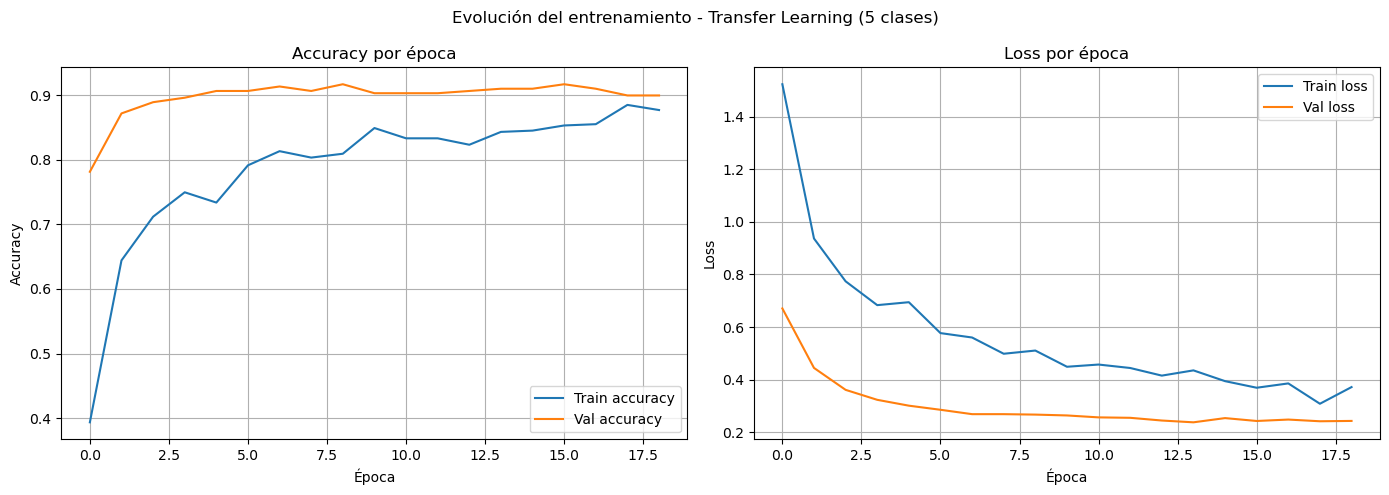

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(historial.history['accuracy'],     label='Train accuracy')
ax1.plot(historial.history['val_accuracy'], label='Val accuracy')
ax1.set_title('Accuracy por época')
ax1.set_xlabel('Época')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True)

ax2.plot(historial.history['loss'],     label='Train loss')
ax2.plot(historial.history['val_loss'], label='Val loss')
ax2.set_title('Loss por época')
ax2.set_xlabel('Época')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True)

plt.suptitle('Evolución del entrenamiento - Transfer Learning (5 clases)')
plt.tight_layout()
plt.show()

## 14. Evaluación del modelo reentrenado

### Matriz de confusión y métricas

In [13]:
# Obtener predicciones sobre el conjunto de test
y_real = []
y_pred = []

for imagenes, etiquetas in test_dataset:
    predicciones = modelo_tl.predict(imagenes, verbose=0)
    y_pred.extend(np.argmax(predicciones, axis=1))
    y_real.extend(np.argmax(etiquetas.numpy(), axis=1))

y_real = np.array(y_real)
y_pred = np.array(y_pred)

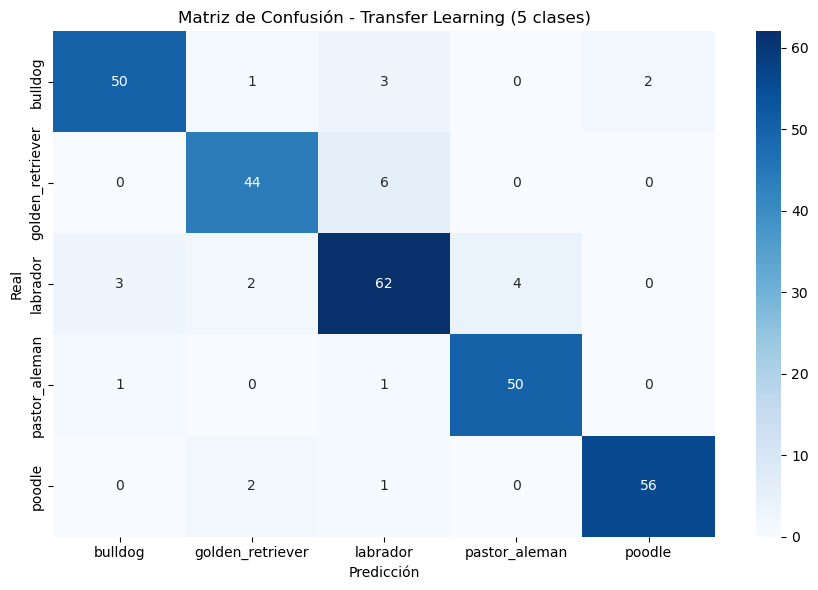

In [14]:
# Matriz de confusión
mc = confusion_matrix(y_real, y_pred)

plt.figure(figsize=(9, 6))
sns.heatmap(mc, annot=True, fmt='d', cmap='Blues',
            xticklabels=clases, yticklabels=clases)
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.title('Matriz de Confusión - Transfer Learning (5 clases)')
plt.tight_layout()
plt.show()

In [15]:
# Métricas
print('=' * 50)
print('    MÉTRICAS DE EVALUACIÓN - TRANSFER LEARNING')
print('=' * 50)
print(f'Accuracy : {accuracy_score(y_real, y_pred):.4f}')
print(f'Precision: {precision_score(y_real, y_pred, average="macro"):.4f}')
print(f'Recall   : {recall_score(y_real, y_pred, average="macro"):.4f}')
print(f'F1-score : {f1_score(y_real, y_pred, average="macro"):.4f}')
print()
print('Informe detallado por clase:')
print(classification_report(y_real, y_pred, target_names=clases))

    MÉTRICAS DE EVALUACIÓN - TRANSFER LEARNING
Accuracy : 0.9097
Precision: 0.9129
Recall   : 0.9114
F1-score : 0.9120

Informe detallado por clase:
                  precision    recall  f1-score   support

         bulldog       0.93      0.89      0.91        56
golden_retriever       0.90      0.88      0.89        50
        labrador       0.85      0.87      0.86        71
   pastor_aleman       0.93      0.96      0.94        52
          poodle       0.97      0.95      0.96        59

        accuracy                           0.91       288
       macro avg       0.91      0.91      0.91       288
    weighted avg       0.91      0.91      0.91       288



## 15. Probar el modelo con imágenes nuevas

Se recorren las imágenes de la carpeta `prueba` y se clasifican con el modelo reentrenado.

In [16]:
for nombre_archivo in os.listdir(carpeta_prueba):
    ruta_imagen = os.path.join(carpeta_prueba, nombre_archivo)
    if ruta_imagen.endswith(('.jpg', '.jpeg', '.png')):
        imagen = Image.open(ruta_imagen).convert('RGB').resize((tam_imagen, tam_imagen))
        imagen = np.array(imagen) / 255
        # Añadir dimensión batch
        imagen = imagen[np.newaxis, ...]
        resultado = modelo_tl.predict(imagen, verbose=0)
        indice = np.argmax(resultado[0])
        clase = clases[indice]
        print(f'Clase: {clase}')
        print(f'Probabilidades: {resultado[0]}')
        print(f'Archivo: {nombre_archivo}')
        print()

Clase: bulldog
Probabilidades: [9.99252260e-01 1.74330830e-06 6.20854611e-04 1.17038406e-04
 8.08249933e-06]
Archivo: bulldog_prueba.jpg

Clase: golden_retriever
Probabilidades: [3.0034939e-06 9.9860495e-01 1.2501986e-03 1.2727415e-05 1.2914689e-04]
Archivo: golden_retriever_prueba.jpg

Clase: labrador
Probabilidades: [3.3548131e-04 4.4918612e-01 5.4705220e-01 2.7417924e-04 3.1519358e-03]
Archivo: labrador_prueba.jpg

Clase: pastor_aleman
Probabilidades: [6.6742644e-04 1.2869398e-04 2.6333105e-04 9.9893278e-01 7.7619279e-06]
Archivo: pastor_aleman_prueba.jpg

Clase: poodle
Probabilidades: [1.26351864e-04 8.47747651e-05 1.10586014e-04 3.02849799e-06
 9.99675274e-01]
Archivo: poodle_prueba.jpg



## 16. Guardar el modelo reentrenado

In [17]:
modelo_tl.save('modelo_perros_5clases.keras')
print('Modelo reentrenado guardado correctamente como modelo_perros_5clases.keras')

Modelo reentrenado guardado correctamente como modelo_perros_5clases.keras
